![Banner](../images/09_11_banner_rs_foundation_models.png)

# Benchmarking Foundation Models on Your Own Data

Published benchmarks rank foundation models on their datasets, with their preprocessing and their
splits. Your sensor, region, classes and label budget are different, and rankings change with all of
them. This notebook builds one evaluation harness and runs every suitable model of the chapter
through it on two tasks: EuroSAT scene classification from RGB, and early-season corn and soybean
mapping from Sentinel-2. It measures accuracy with probes, label efficiency, speed and memory, keeps
simple baselines in every table, and ends with a decision guide drawn from the results.

## Overview

### What to measure

| Quantity | Why it matters | How |
|---|---|---|
| accuracy of frozen embeddings | how much the encoder already knows | linear and kNN probes |
| label efficiency | the reason to use a foundation model at all | accuracy with few labels per class |
| spatial generalization | maps are used where no labels exist | spatial or grouped cross-validation |
| speed and memory | cost of mapping a region or an archive | seconds per 1000 chips, peak GPU memory |
| licence and access | whether the model can be used at all | model card |

### A fair comparison

1. **Same samples, same folds** for every model, including the baselines.
2. **Each model's own input contract** (bands, units, statistics), so no model is handicapped by
   wrong preprocessing; a deliberately mismatched model shows what that would cost.
3. **Baselines** that need no foundation model: simple statistics of the bands, and a small network
   trained from scratch.
4. **Spread, not just means**: the fold-to-fold standard deviation says which differences matter.
5. **Spatial hold-outs** wherever the samples have coordinates.

### Why probes

A linear probe trains only a linear classifier on frozen embeddings; a kNN probe uses the raw
distances. Both are cheap, deterministic and comparable across models. Fine-tuning can change the
ranking (notebook 09_11_04 showed a U-Net beating a frozen and a fine-tuned Prithvi on segmentation),
so probes measure what the embeddings hold, not the best achievable accuracy.

## Benchmarking with GeoLattice

`fm.benchmark_encoders(inputs, y, groups=)` loads each model, embeds its prepared chips (or takes
precomputed embeddings for baselines), runs linear and kNN probes with the same folds, and reports
embedding size, parameters, seconds per 1000 chips and peak GPU memory.

### Learning objectives

1. Prepare one labelled set for many models, each with its own input contract.
2. Run linear and kNN probes with identical folds for models and baselines.
3. Measure label efficiency with few labels per class.
4. Measure speed and GPU memory, and plot accuracy against cost.
5. Compare rankings across two tasks and turn them into a decision guide.

### Data

| Task | Samples | Labels | Folds |
|---|---|---|---|
| EuroSAT RGB | 2,000 images (200 per class), 64 px resized to the model size | 10 land use classes | stratified 5-fold |
| Corn Belt, 22 June 2025 | 640 m cells of a 30 x 29 km Sentinel-2 scene | corn or soybean (CDL 2025) | 5-fold over 5.8 km blocks |

### Contents

- Setup
- Task 1: EuroSAT RGB
- Label efficiency on EuroSAT
- Task 2: early-season crops in the Corn Belt
- Accuracy against cost
- Do the rankings agree?
- A decision guide
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

import zipfile  # EuroSAT archive
from PIL import Image  # images
CUBE = IC / "Corn_belt" / "cache_20m"  # Corn Belt cubes
CLIP_MEAN, CLIP_STD = [0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711]  # CLIP image statistics

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## Task 1: EuroSAT RGB

Two hundred images per class are drawn from EuroSAT. Every model gets the same images, resized to its
input size and normalized by its contract: ImageNet statistics for Scale-MAE, 0 to 1 for Satlas NAIP,
CLIP statistics for RemoteCLIP and GeoRSCLIP, per-band standardization for DOFA and Panopticon (told
the band wavelengths). The SSL4EO ResNet-18 expects thirteen Sentinel-2 bands; it receives the RGB
bands with the other ten filled from the nearest of them, as a deliberately mismatched entry.

In [2]:
zf = zipfile.ZipFile(CAP / "EuroSat.zip")  # the archive
files = np.array([n for n in zf.namelist() if n.endswith(".jpg")])  # every image
cls = np.array([n.split("/")[1] for n in files])  # class names
rng = np.random.default_rng(SEED)  # random generator
pick = np.concatenate([rng.choice(np.flatnonzero(cls == c), 200, replace=False) for c in np.unique(cls)])  # 200 per class
rgb64 = np.stack([np.asarray(Image.open(zf.open(f)).convert("RGB"), "float32") / 255 for f in files[pick]])  # (2000, 64, 64, 3)
y_es = cls[pick]  # labels
x64 = torch.as_tensor(rgb64).permute(0, 3, 1, 2)  # (2000, 3, 64, 64)
up = lambda s: torch.nn.functional.interpolate(x64, size=s, mode="bicubic", align_corners=False).clamp(0, 1)  # resize


def norm(x, mean, std):  # channel-wise normalization
    return ((x - torch.tensor(mean)[:, None, None]) / torch.tensor(std)[:, None, None]).numpy()  # (n, 3, s, s)


def standardize(x):  # per-band standardization over the whole set
    return ((x - x.mean((0, 2, 3), keepdim=True)) / x.std((0, 2, 3), keepdim=True)).numpy()  # (n, 3, s, s)


x224 = up(224)  # RGB at 224 px
bands13 = fm.input_spec("ssl4eo-s12-resnet18-moco")["bands"]  # the 13 bands SSL4EO expects
order13 = [["red", "green", "blue"].index(b) if b in ("red", "green", "blue") else
           ["red", "green", "blue"].index(min(["red", "green", "blue"], key=lambda c: abs(fm.WAVELENGTHS_NM[c] - fm.WAVELENGTHS_NM[b])))
           for b in bands13]  # nearest RGB band for each of the 13
print("SSL4EO bands filled from RGB:", [b for b in bands13 if b not in ("red", "green", "blue")])  # the mismatch

inputs_es = {
    "RGB mean and std (baseline)": {"embeddings": np.c_[rgb64.mean((1, 2)), rgb64.std((1, 2))]},  # 6 numbers
    "colour histogram (baseline)": {"embeddings": np.concatenate([np.stack([np.histogram(im[..., c], 16, (0, 1))[0] for im in rgb64]) for c in range(3)], 1) / 4096},  # 48 numbers
    "scale-mae": {"x": norm(x224, fm.input_spec("scale-mae")["mean"], fm.input_spec("scale-mae")["std"])},  # ImageNet statistics
    "satlas-swinb-naip": {"x": up(256).numpy()},  # 0..1, 256 px
    "remoteclip-vit-b-32": {"x": norm(x224, CLIP_MEAN, CLIP_STD)},  # CLIP statistics
    "georsclip-vit-b-32": {"x": norm(x224, CLIP_MEAN, CLIP_STD)},  # CLIP statistics
    "dofa-base": {"x": standardize(x224), "load": {"bands": ["red", "green", "blue"]}},  # wavelengths from band names
    "panopticon": {"x": standardize(x224), "load": {"bands": ["red", "green", "blue"]}},  # wavelengths from band names
    "ssl4eo-s12-resnet18-moco (mismatched)": {"model": "ssl4eo-s12-resnet18-moco",
                                              "x": x224.numpy()[:, order13] * 1.0},  # RGB copied into 13 bands
}
t0 = time.perf_counter()  # start the clock
bench_es = fm.benchmark_encoders(inputs_es, y_es, cv=5, device=DEVICE, batch_size=64)  # probes, speed, memory
print(f"{time.perf_counter() - t0:.0f} s")  # total time
bench_es.round(3).sort_values("linear_f1_macro", ascending=False)  # ranked

SSL4EO bands filled from RGB: ['coastal', 'rededge1', 'rededge2', 'rededge3', 'nir', 'nir08', 'watervapor', 'cirrus', 'swir16', 'swir22']


281 s


,params_m,s_per_1000,gpu_mb,embed_dim,linear_accuracy,linear_f1_macro,knn_accuracy
input,,,,,,,
panopticon,98.120,11.846,2920.113,768,0.962,0.962,0.916
georsclip-vit-b-32,151.277,1.639,739.226,512,0.961,0.961,0.923
dofa-base,111.347,6.549,877.259,768,0.951,0.951,0.895
scale-mae,303.302,22.099,1799.129,1024,0.948,0.947,0.838
satlas-swinb-naip,86.906,10.077,1927.766,1024,0.946,0.946,0.857
remoteclip-vit-b-32,151.277,1.626,739.226,512,0.932,0.932,0.896
ssl4eo-s12-resnet18-moco (mismatched),11.208,0.882,603.056,512,0.923,0.923,0.887
RGB mean and std (baseline),0.000,NaN,NaN,6,0.659,0.651,0.659
colour histogram (baseline),0.000,NaN,NaN,48,0.632,0.628,0.625


A small CNN trained from scratch on the same images and folds is the second baseline: four
convolution blocks, 20 epochs per fold.

In [3]:
from sklearn.metrics import f1_score  # scores
from sklearn.model_selection import StratifiedKFold  # same folds as the probes

classes = sorted(np.unique(y_es)); yi = np.array([classes.index(c) for c in y_es])  # class indices


def small_cnn():  # four conv blocks for 64 px RGB
    blk = lambda i, o: torch.nn.Sequential(torch.nn.Conv2d(i, o, 3, padding=1), torch.nn.BatchNorm2d(o), torch.nn.ReLU(), torch.nn.MaxPool2d(2))  # one block
    return torch.nn.Sequential(blk(3, 32), blk(32, 64), blk(64, 128), blk(128, 128), torch.nn.AdaptiveAvgPool2d(1),
                               torch.nn.Flatten(), torch.nn.Linear(128, 10))  # network


f1s, t0 = [], time.perf_counter()  # fold scores and timing
for k, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(yi, yi)):  # same folds as fm.linear_probe
    torch.manual_seed(SEED); net = small_cnn().to(DEVICE)  # fresh network
    opt = torch.optim.AdamW(net.parameters(), 2e-3)  # optimizer
    X, Y = x64[tr].to(DEVICE), torch.as_tensor(yi[tr]).to(DEVICE)  # training data
    for ep in range(20):  # epochs
        net.train()  # training mode
        for i in torch.randperm(len(tr)).split(64):  # mini-batches
            xb = X[i].flip(-1) if ep % 2 else X[i]  # flip every other epoch
            loss = torch.nn.functional.cross_entropy(net(xb), Y[i]); opt.zero_grad(); loss.backward(); opt.step()  # update
    net.eval()  # evaluation mode
    with torch.no_grad():  # inference
        pred = net(x64[te].to(DEVICE)).argmax(1).cpu().numpy()  # predictions
    f1s.append(f1_score(yi[te], pred, average="macro"))  # fold score
cnn_row = pd.DataFrame({"linear_f1_macro": [np.mean(f1s)], "s_per_1000": [np.nan], "embed_dim": [np.nan]},
                       index=["small CNN from scratch (baseline)"])  # one row
print(f"small CNN: macro F1 {np.mean(f1s):.3f} +/- {np.std(f1s):.3f} in {time.perf_counter() - t0:.0f} s")  # result

small CNN: macro F1 0.693 +/- 0.054 in 14 s


Every foundation model beats both baselines by a wide margin: linear probes on frozen embeddings reach
a macro F1 of 0.92 to 0.96, against about 0.65 for six RGB statistics, 0.63 for colour histograms and
0.69 for the small CNN trained from scratch on 1,600 images per fold. (A CNN trained longer, with
augmentation, on all 27,000 EuroSAT images reaches far higher; with this small labelled set it cannot.)
Panopticon and GeoRSCLIP lead at about 0.96, and GeoRSCLIP embeds a thousand chips in under 2 seconds
against 12 for Panopticon and 22 for Scale-MAE. The deliberately mismatched SSL4EO ResNet-18, which
received RGB copied into thirteen bands, still reaches 0.92: EuroSAT is forgiving, and the mismatch
costs only three to four points here. The kNN scores, which use raw distances, are lower and spread
more, because embedding spaces differ in how well plain distance reflects the classes.

## Label efficiency on EuroSAT

Foundation models should matter most when labels are scarce. A logistic regression is trained on 2, 5,
10 and 50 images per class from the first fold's training images and scored on its test images, five
draws each. The embeddings are recomputed once per model.

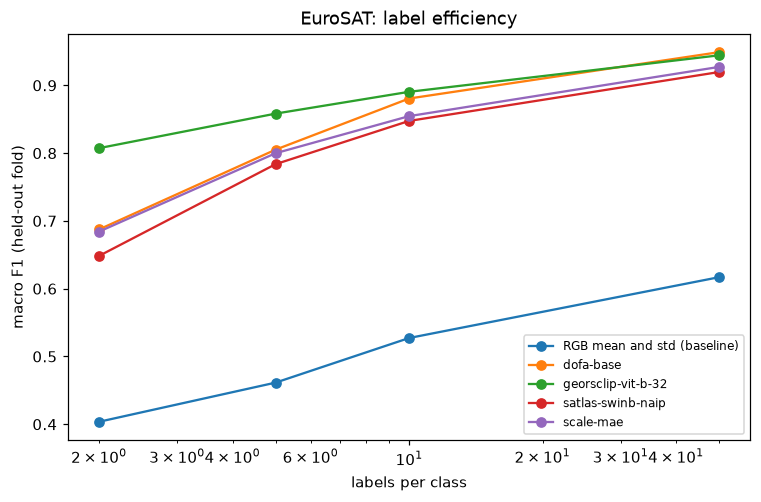

input,RGB mean and std (baseline),dofa-base,georsclip-vit-b-32,satlas-swinb-naip,scale-mae
labels per class,,,,,
2,0.404,0.687,0.807,0.648,0.684
5,0.461,0.805,0.858,0.784,0.800
10,0.527,0.881,0.890,0.848,0.855
50,0.617,0.949,0.944,0.920,0.927


In [4]:
from sklearn.linear_model import LogisticRegression  # classifier
from sklearn.pipeline import make_pipeline  # scaling + model
from sklearn.preprocessing import StandardScaler  # scaling

tr, te = next(StratifiedKFold(5, shuffle=True, random_state=SEED).split(yi, yi))  # first fold
EMB = {"RGB mean and std (baseline)": inputs_es["RGB mean and std (baseline)"]["embeddings"]}  # baseline features
for n in ["scale-mae", "satlas-swinb-naip", "georsclip-vit-b-32", "dofa-base"]:  # four models
    spec = inputs_es[n]; e = fm.load_model(spec.get("model", n), device=DEVICE, **spec.get("load", {}))  # load
    EMB[n] = e.embed(spec["x"], batch_size=64); del e; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # embeddings
rows = []  # label efficiency
for k in [2, 5, 10, 50]:  # labels per class
    for rep in range(5):  # draws
        r = np.random.default_rng(rep)  # generator
        idx = np.concatenate([r.choice(tr[yi[tr] == c], k, replace=False) for c in range(10)])  # k per class
        for n, E in EMB.items():  # every input
            clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(E[idx], yi[idx])  # train
            rows.append({"labels per class": k, "input": n, "F1": f1_score(yi[te], clf.predict(E[te]), average="macro")})  # score
eff = pd.DataFrame(rows).groupby(["labels per class", "input"])["F1"].mean().unstack()  # mean over draws
ax = eff.plot(marker="o", logx=True, figsize=(8, 4.8)); ax.set_ylabel("macro F1 (held-out fold)")  # curves
ax.set_title("EuroSAT: label efficiency"); ax.legend(fontsize=8); plt.show()  # draw
eff.round(3)

With two labelled images per class GeoRSCLIP reaches about 0.81, well ahead of DOFA, Scale-MAE and
Satlas (0.65 to 0.69): its image-text pretraining on captioned overhead scenes already groups EuroSAT's
land use classes. The gap closes as labels grow, and at 50 per class DOFA (about 0.95) and GeoRSCLIP are
level, with Scale-MAE and Satlas a little behind. The RGB baseline stays far below at every size. Which
model is best depends on how many labels you have.

## Task 2: early-season crops in the Corn Belt

The second task repeats the June experiment of notebook 09_11_04 with more encoders: each model reads
the 22 June 2025 scene at native resolution with its own contract, its patch features are averaged to
640 m cells, and the cells are probed with folds over 5.8 km blocks. Run time and peak GPU memory are
measured for the whole scene. Copernicus-FM, Panopticon and CROMA return pooled vectors only and are
left out of this patch-level comparison (notebook 09_11_05 evaluates them at chip level).

In [5]:
s2 = xr.open_dataarray(CUBE / "s2_20m.nc").sel(time="2025-06-22").drop_vars("time").load().rio.write_crs("EPSG:32615")  # June scene
cdl = xr.open_dataset(CUBE / "labels_20m.nc")["cdl"].sel(year=2025).load()  # CDL 2025
CELL = 32; NY, NX = -(-cdl.shape[0] // CELL), -(-cdl.shape[1] // CELL)  # 640 m cell grid
pad = np.full((NY * CELL, NX * CELL), -1, cdl.dtype); pad[:cdl.shape[0], :cdl.shape[1]] = cdl.values  # padded CDL
blk = pad.reshape(NY, CELL, NX, CELL).transpose(0, 2, 1, 3).reshape(NY * NX, -1)  # pixels per cell
cnt = np.stack([(blk == k).sum(1) for k in (0, 1)], 1); y_cb, pur = cnt.argmax(1), cnt.max(1) / blk.shape[1]  # labels
gy, gx = np.divmod(np.arange(NY * NX), NX); group = (gy // 9) * 10 + gx // 9; ok = pur >= 0.6  # blocks and usable cells


def cells(d):  # patch map -> (cells, D) on the 640 m grid
    f = int(round(d.sizes["y"] / NY))  # patches per cell side
    d = d.coarsen(y=f, x=f, boundary="pad").mean() if f > 1 else d  # average to 640 m
    return d.values[:, :NY, :NX].reshape(d.sizes["embedding"], -1).T  # (cells, D)


CB_MODELS = ["prithvi-eo-2.0-300m", "prithvi-eo-1.0-100m", "terramind-v1-base", "ssl4eo-s12-vits16-dino",
             "ssl4eo-s12-resnet18-moco", "satlas-swint-s2-ms", "dofa-base", "scale-mae"]  # patch-capable encoders
inputs_cb = {"band means (baseline)": {"embeddings": np.nan_to_num(s2.coarsen(y=CELL, x=CELL, boundary="pad").mean().values[:, :NY, :NX].reshape(10, -1).T)[ok]}}  # baseline
cost = {}  # time and memory per model
for n in CB_MODELS:  # every encoder
    e = fm.load_model(n, device=DEVICE)  # load
    if DEVICE == "cuda":  # reset the memory counter
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()  # start clean
    t0 = time.perf_counter()  # start the clock
    E = cells(e.embed_raster(s2, dense=True, norm="model", batch_size=8))  # (cells, D)
    if DEVICE == "cuda":  # wait for the GPU
        torch.cuda.synchronize()  # finish
    cost[n] = {"seconds for the scene": time.perf_counter() - t0, "params (M)": sum(p.numel() for p in e.model.parameters()) / 1e6,
               "peak GPU memory (MB)": torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else np.nan}  # cost
    inputs_cb[n] = {"embeddings": E[ok]}  # features of usable cells
    del e; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
bench_cb = fm.benchmark_encoders(inputs_cb, y_cb[ok], groups=group[ok], cv=5).join(pd.DataFrame(cost).T)  # probes + cost
bench_cb[["embed_dim", "linear_f1_macro", "knn_accuracy", "seconds for the scene", "params (M)", "peak GPU memory (MB)"]].round(3).sort_values("linear_f1_macro", ascending=False)  # ranked

,embed_dim,linear_f1_macro,knn_accuracy,seconds for the scene,params (M),peak GPU memory (MB)
input,,,,,,
terramind-v1-base,768,0.975,0.948,0.579,87.314,2063.581
prithvi-eo-2.0-300m,1024,0.958,0.928,0.854,303.886,1477.491
ssl4eo-s12-vits16-dino,384,0.955,0.939,0.444,22.649,1734.400
dofa-base,768,0.940,0.915,0.622,111.347,2085.421
scale-mae,1024,0.939,0.895,0.798,303.302,2825.631
prithvi-eo-1.0-100m,768,0.918,0.932,0.442,86.237,1699.927
satlas-swint-s2-ms,768,0.905,0.819,0.328,27.592,1859.246
band means (baseline),10,0.889,0.879,NaN,NaN,NaN
ssl4eo-s12-resnet18-moco,512,0.643,0.680,0.365,11.208,1726.964


On early-season crops the ranking changes. TerraMind leads (macro F1 about 0.975), followed by
Prithvi-EO-2.0 and the SSL4EO ViT (about 0.96), all models pretrained on Sentinel-2 or HLS with time in
their training data. DOFA and Scale-MAE follow at about 0.94, the smaller Prithvi-EO-1.0 at 0.92 and
Satlas at 0.91, all above the band means (0.89). The SSL4EO ResNet-18 falls far below the baseline
(0.64). Its 640 m cells come from the last stage of a ResNet run on 224 pixel chips, so each cell mixes
a wide neighbourhood. In notebook 09_11_03, where the same weights read 640 m chips resized to 224
pixels, they reached 0.96. How features are extracted matters as much as which weights are used. All
models embed the 30 x 29 km scene in under a second on the GPU, so speed does not decide here.

## Accuracy against cost

Accuracy alone does not choose a model: a model twice as slow must be clearly better to be worth it
for a large area.

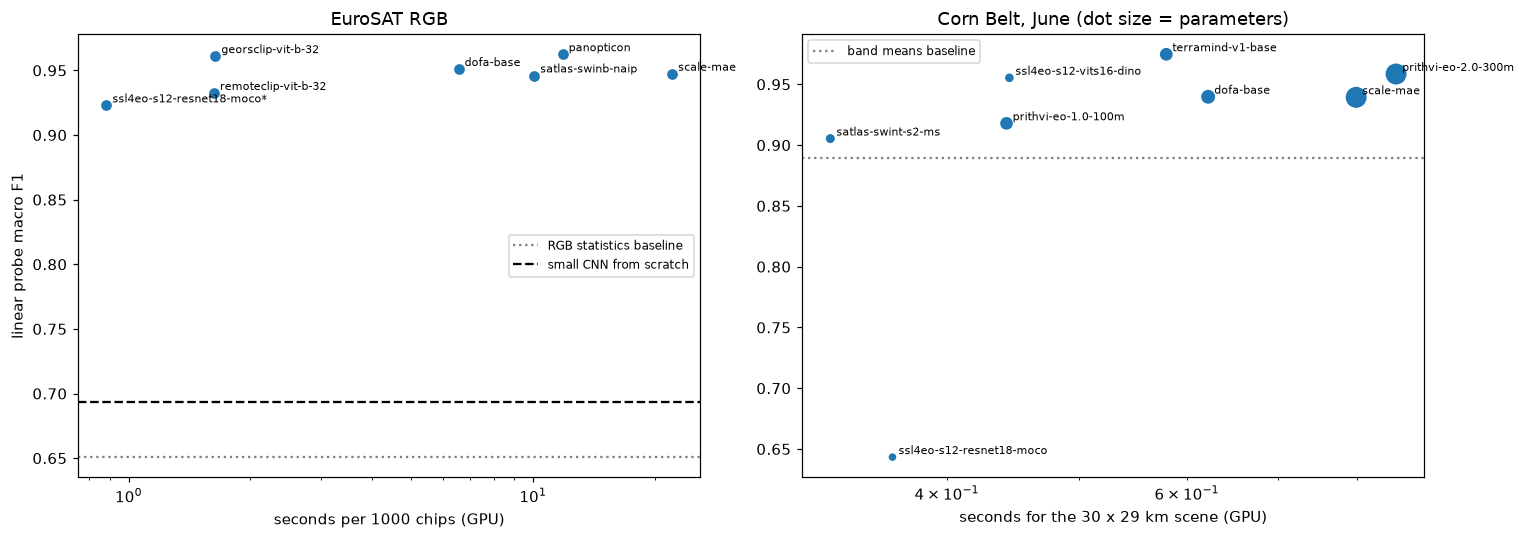

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # two tasks
es = bench_es.dropna(subset=["s_per_1000"])  # models with a measured cost
ax[0].scatter(es["s_per_1000"], es["linear_f1_macro"])  # EuroSAT points
for n, r in es.iterrows():  # labels
    ax[0].annotate(n.replace(" (mismatched)", "*"), (r["s_per_1000"], r["linear_f1_macro"]), fontsize=7, xytext=(4, 2), textcoords="offset points")  # name
ax[0].axhline(bench_es.loc["RGB mean and std (baseline)", "linear_f1_macro"], ls=":", c="gray", label="RGB statistics baseline")  # baseline
ax[0].axhline(np.mean(f1s), ls="--", c="k", label="small CNN from scratch"); ax[0].legend(fontsize=8)  # CNN
ax[0].set_xscale("log"); ax[0].set_xlabel("seconds per 1000 chips (GPU)"); ax[0].set_ylabel("linear probe macro F1"); ax[0].set_title("EuroSAT RGB")  # labels
cb = bench_cb.dropna(subset=["seconds for the scene"])  # encoders
ax[1].scatter(cb["seconds for the scene"], cb["linear_f1_macro"], s=cb["params (M)"] / 2 + 10)  # size = parameters
for n, r in cb.iterrows():  # labels
    ax[1].annotate(n, (r["seconds for the scene"], r["linear_f1_macro"]), fontsize=7, xytext=(4, 2), textcoords="offset points")  # name
ax[1].axhline(bench_cb.loc["band means (baseline)", "linear_f1_macro"], ls=":", c="gray", label="band means baseline"); ax[1].legend(fontsize=8)  # baseline
ax[1].set_xscale("log"); ax[1].set_xlabel("seconds for the 30 x 29 km scene (GPU)"); ax[1].set_title("Corn Belt, June (dot size = parameters)")  # labels
plt.tight_layout(); plt.show()  # draw

## Do the rankings agree?

Three models ran on both tasks. If benchmark rankings transferred between tasks, their order would
be the same.

In [7]:
both = [n for n in ["scale-mae", "dofa-base", "ssl4eo-s12-resnet18-moco"] if n in bench_cb.index]  # models in both tables
es_name = {n: (n if n in bench_es.index else n + " (mismatched)") for n in both}  # EuroSAT row names
comp = pd.DataFrame({"EuroSAT RGB F1": {n: bench_es.loc[es_name[n], "linear_f1_macro"] for n in both},
                     "Corn Belt June F1": {n: bench_cb.loc[n, "linear_f1_macro"] for n in both}})  # side by side
comp["EuroSAT rank"] = comp["EuroSAT RGB F1"].rank(ascending=False).astype(int)  # rank on task 1
comp["Corn Belt rank"] = comp["Corn Belt June F1"].rank(ascending=False).astype(int)  # rank on task 2
comp.round(3)

,EuroSAT RGB F1,Corn Belt June F1,EuroSAT rank,Corn Belt rank
scale-mae,0.947,0.939,2,2
dofa-base,0.951,0.940,1,1
ssl4eo-s12-resnet18-moco,0.923,0.643,3,3


For the three models that ran on both tasks the order is the same (DOFA, Scale-MAE, SSL4EO ResNet-18),
but the scale of the differences is not: the ResNet is two points behind on EuroSAT and thirty points
behind on the crops. Across all models the leaders differ: Panopticon and GeoRSCLIP lead on EuroSAT RGB,
TerraMind and Prithvi on Sentinel-2 crops, and GeoRSCLIP cannot run on the crop task at all (RGB only).
A ranking holds for the data, preprocessing and label budget it was measured on.

## A decision guide

Drawn from this chapter's measurements, not from published leaderboards:

| Situation | Start with | Then compare with |
|---|---|---|
| Sentinel-2 or HLS, crops or land cover, few dates | Prithvi-EO-2.0, TerraMind, SSL4EO ViT (patch features) | band means or indices + random forest |
| early season, several dates | Prithvi-EO-2.0-TL with dates (notebook 09_11_06) | NDVI series + random forest |
| RGB scenes, few labels | GeoRSCLIP or RemoteCLIP embeddings + linear probe | DOFA, Panopticon |
| unusual band sets or several sensors | Panopticon (transferred best between sensors in 09_11_05), DOFA | band values of the shared bands |
| radar with optical | CROMA radar embedding where clouds are frequent | Sentinel-1 band statistics |
| pixel-level segmentation with labels | a U-Net trained from scratch (won in 09_11_04) | Prithvi + UperNet, frozen and fine-tuned |
| very high resolution | Scale-MAE or Satlas NAIP features, SAM 2 for outlines (09_11_09) | RGB statistics |
| no GPU, annual maps or covariates | AlphaEarth embeddings (perfect on 2024 crops in 09_11_07; below classical covariates for soil carbon in 09_11_08) | classical covariates |

Always keep one simple baseline and spatial folds in the comparison, and check the model's input
contract (`fm.input_spec`) before reading any score.

## Summary and exercises

### Summary

- A fair benchmark uses the same samples and folds for every model, each model's own input contract,
  simple baselines, fold-to-fold spread and spatial hold-outs.
- `fm.benchmark_encoders` gives probe scores, embedding size, parameters, speed and GPU memory in one
  table, for loaded models and for precomputed baselines.
- On EuroSAT RGB and on early-season Sentinel-2 crops the best models differ, and a model fed inputs
  outside its contract falls behind.
- Label efficiency, speed and licence matter as much as the top score.
- Rankings from one task or benchmark do not transfer automatically: evaluate on your own data.

### Exercises

1. Add `remoteclip-vit-l-14` and `dofa-large` to the EuroSAT benchmark. Are larger models worth their cost?
2. Run the EuroSAT benchmark on the CPU only (`device="cpu"`) and recompute the cost plot.
3. Replace the Corn Belt June scene with 14 July and see whether the ranking changes.
4. Add a random forest on the 10 band means and NDVI as a third Corn Belt baseline.
5. Write a function that runs `fm.benchmark_encoders` for 2, 5 and 20 labels per class and returns one
   table, so label efficiency becomes part of every benchmark.

### References

- Lacoste, A. et al. (2023). GEO-Bench. NeurIPS Datasets and Benchmarks.
- Marsocci, V. et al. (2024). PANGAEA: a global and inclusive benchmark for geospatial foundation models. arXiv:2412.04204.
- Helber, P. et al. (2019). EuroSAT. IEEE JSTARS.
- Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. Ecography.